Finite Potential Well (a = 1.0, V0 = 20.0):
n = 1 (even): Numerical = 0.920267, Analytical = 0.917870, Error = 2.40e-03
n = 2 (odd): Numerical = 3.655426, Analytical = 3.646201, Error = 9.22e-03
n = 3 (even): Numerical = 8.111476, Analytical = 8.092151, Error = 1.93e-02
n = 4 (odd): Numerical = 14.032196, Analytical = 14.002160, Error = 3.00e-02
n = 5 (even): Numerical = 20.040477, Analytical = 19.972583, Error = 6.79e-02


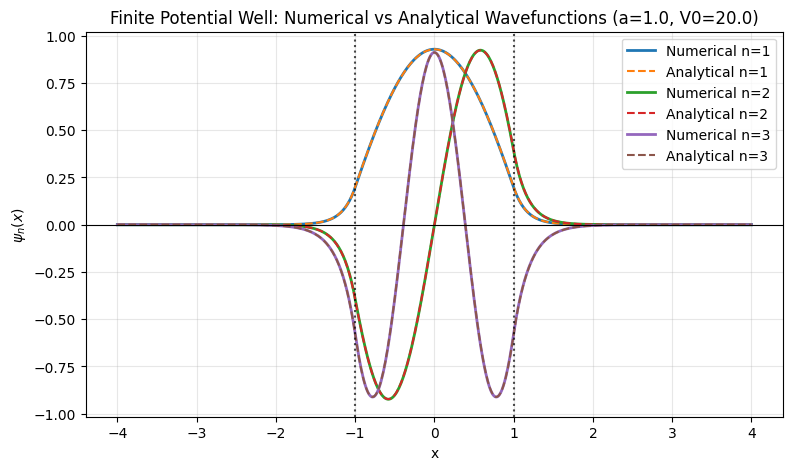

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def build_hamiltonian(dx, V):
    n = len(V)
    main_diag = 1.0 / (dx**2) + V
    off_diag = np.full(n - 1, -0.5 / (dx**2))
    return np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)

def finite_well_potential(x, a, V0):
    return np.where(np.abs(x) <= a, 0.0, V0)

def solve_finite_well_fd(xi, xf, N, a, V0):
    dx = (xf - xi) / (N + 1)
    x_int = xi + dx * np.arange(1, N + 1)
    V = finite_well_potential(x_int, a, V0)
    H = build_hamiltonian(dx, V)
    evals, evecs = np.linalg.eigh(H)

    x_full = np.concatenate(([xi], x_int, [xf]))
    psi_list = []
    for i in range(N):
        psi = np.concatenate(([0.0], evecs[:, i], [0.0]))
        norm = np.sqrt(np.sum(np.abs(psi)**2) * dx)
        psi_list.append(psi / norm)

    return x_full, evals, psi_list

def bisect(func, low, high, tol=1e-10, max_iter=1000):
    fl = func(low)
    for _ in range(max_iter):
        mid = 0.5 * (low + high)
        fm = func(mid)
        if abs(fm) < tol or abs(high - low) < tol:
            return mid
        if fl * fm < 0:
            high = mid
        else:
            low = mid
            fl = fm
    return 0.5 * (low + high)

def solve_finite_well_analytical(a, V0):
    z0 = a * np.sqrt(2.0 * V0)
    eps = 1e-10
    edges = list(np.arange(0.0, z0, np.pi / 2.0))
    if edges[-1] < z0:
        edges.append(z0)

    states = []
    for i in range(len(edges) - 1):
        l = edges[i] + eps
        r = edges[i + 1] - eps
        if l >= r:
            continue

        parity = "even" if i % 2 == 0 else "odd"
        if parity == "even":
            f = lambda z: z * np.tan(z) - np.sqrt(np.clip(z0**2 - z**2, 0.0, None))
        else:
            f = lambda z: -z / np.tan(z) - np.sqrt(np.clip(z0**2 - z**2, 0.0, None))

        if f(l) * f(r) < 0:
            z = bisect(f, l, r)
            E = (z**2) / (2.0 * a**2)
            k = z / a
            kappa = np.sqrt(2.0 * (V0 - E))
            if parity == "even":
                A = 1.0 / np.sqrt(a + (a * np.sin(2.0 * z)) / (2.0 * z) + (np.cos(z)**2) / kappa)
            else:
                A = 1.0 / np.sqrt(a - (a * np.sin(2.0 * z)) / (2.0 * z) + (np.sin(z)**2) / kappa)
            states.append((E, parity, z, k, kappa, A))

    states.sort(key=lambda s: s[0])
    return states

def analytical_psi(x, state, a):
    _, parity, z, k, kappa, A = state
    if parity == "even":
        inside = A * np.cos(k * x)
        outside = A * np.cos(z) * np.exp(-kappa * (np.abs(x) - a))
    else:
        inside = A * np.sin(k * x)
        outside = np.sign(x) * A * np.sin(z) * np.exp(-kappa * (np.abs(x) - a))
    return np.where(np.abs(x) <= a, inside, outside)

a = 1.0
V0 = 20.0
xi = -4.0
xf = 4.0
N = 600

x, E_num, psi_num = solve_finite_well_fd(xi, xf, N, a, V0)
ana_states = solve_finite_well_analytical(a, V0)
n_bound = len(ana_states)

print(f"Finite Potential Well (a = {a}, V0 = {V0}):")
for i in range(n_bound):
    E_a = ana_states[i][0]
    err = abs(E_num[i] - E_a)
    print(f"n = {i+1} ({ana_states[i][1]}): Numerical = {E_num[i]:.6f}, Analytical = {E_a:.6f}, Error = {err:.2e}")

plt.figure(figsize=(9, 5))
for i in range(min(3, n_bound)):
    psi_a = analytical_psi(x, ana_states[i], a)
    psi_n = psi_num[i]
    if np.dot(psi_n, psi_a) < 0:
        psi_n = -psi_n
    plt.plot(x, psi_n, label=f"Numerical n={i+1}", linewidth=2)
    plt.plot(x, psi_a, "--", label=f"Analytical n={i+1}", linewidth=1.5)

plt.axvline(-a, color="black", linestyle=":", alpha=0.7)
plt.axvline(a, color="black", linestyle=":", alpha=0.7)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel(r"$\psi_n(x)$")
plt.title(f"Finite Potential Well: Numerical vs Analytical Wavefunctions (a={a}, V0={V0})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()